# ACTIVIDAD #4 DE GESTION DE PROYECTOS DE IA
# PROYECTO OVARA — Detección de endometrioma en resonancia magnética (comparación de 3 modelos)

**Tarea:** Para esta actividad voy a clasificar cada corte de resonancia (secuencia **T2**) como *con endometrioma* (1) o *sin endometrioma* (0).
La etiqueta se obtiene automáticamente de la máscara `_cy` del dataset: si el corte tiene píxeles de quiste, es positivo.

El Dataset con los modelos en 3D se obtuvieron de la siguiente fuente: https://zenodo.org/records/13749613

**Modelos comparados**

| # | Modelo | Tipo |
|---|---|---|
| 1 | CNN propia | Red convolucional pequeña entrenada desde cero (línea base) |
| 2 | ResNet18 | Preentrenada en ImageNet + fine-tuning |
| 3 | EfficientNet-B0 | Preentrenada en ImageNet + fine-tuning |


**Problemas de entorno (Windows + VS Code) que pudieran sucitarse (me pasaron a mi) **

| # | Problema | Causa | Solución |
|---|---|---|---|
| 1 | La instalación de PyTorch falló con `ReadTimeoutError` | El archivo de PyTorch con CUDA pesa ~2.8 GB y la descarga se congeló a la mitad | Instalar desde la terminal con más tolerancia: `python -m pip install torch torchvision --index-url https://download.pytorch.org/whl/cu128 --timeout 300 --retries 10` (alternativa: descargar el `.whl` con el navegador e instalarlo local; desactivar VPN durante la descarga) |
| 2 | `ModuleNotFoundError: No module named 'torch'` en el notebook, aunque en la terminal sí funcionaba | En el equipo hay varios Python 3.11 y el kernel de VS Code usaba uno distinto al de la terminal | Obtener la ruta con `python -c "import sys; print(sys.executable)"` y seleccionar ese intérprete en **Select Kernel → Python Environments** |
| 3 | TensorFlow (usado en DocuAI) no usa la GPU en Windows | TensorFlow dejó de dar soporte GPU nativo en Windows después de la versión 2.10 | Se cambió a **PyTorch**, que sí soporta CUDA en Windows |
| 4 | El notebook dependía de una ruta absoluta del disco | La ruta del dataset estaba fija a `C:\Proyectos\...` | Ruta relativa a la carpeta del notebook (o la variable `OVARA_DATA`) y `requirements.txt` para instalar en otra PC |

**Problemas del dataset y del modelo (prevenidos en el código)**

| # | Riesgo | Solución aplicada |
|---|---|---|
| 5 | Los archivos `.nii.gz` parecían requerir otra descompresión | No se descomprimen: `nibabel` los lee directamente |
| 6 | Algunas máscaras pueden tener distinta resolución que la imagen T2 | Remuestreo automático con `resample_from_to` (vecino más cercano, `order=0`) |
| 7 | `DataLoader` falla con multiprocesamiento en Windows + Jupyter | `NUM_WORKERS = 0` |
| 8 | Métricas infladas si cortes de la misma paciente quedan en entrenamiento y prueba | División **por paciente**, no por corte |
| 9 | `rescale=1/255` (como en DocuAI) no sirve para resonancia, cuya intensidad no tiene escala fija | Normalización por volumen con percentiles 1–99 |
| 10 | Hay muchos más cortes sin quiste que con quiste (desbalance) | `WeightedRandomSampler` para balancear los lotes de entrenamiento |

## 1. Instalación de dependencias

Ejecutar **una sola vez**. En Windows, PyTorch con CUDA se instala desde el índice oficial de PyTorch
(TensorFlow ya no ofrece GPU nativa en Windows, por eso se usa PyTorch).

* Verificar versión de driver con `nvidia-smi` en una terminal. Si el driver es anterior, usar la variante que indique el selector oficial (por ejemplo `cu126`); para RTX 50xx usa `cu128` o superior
  (selector oficial: https://pytorch.org/get-started/locally/).
* Después de instalar, **reinicia el kernel**.

In [51]:
# Descomentar y ejecuta una sola vez:
#%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu128
#%pip install nibabel scipy scikit-learn pandas matplotlib tqdm ipywidgets

In [52]:
import importlib, sys
paquetes = ["torch", "torchvision", "nibabel", "scipy", "sklearn", "pandas", "matplotlib", "tqdm"]
for p in paquetes:
    try:
        m = importlib.import_module(p)
        print(f"  OK  {p:<12} {getattr(m, '__version__', '')}")
    except ImportError:
        print(f"  FALTA {p}  -> instálalo con la celda anterior")
print("Python", sys.version.split()[0])

  OK  torch        2.11.0+cu128
  OK  torchvision  0.26.0+cu128
  OK  nibabel      5.4.2
  OK  scipy        1.16.3
  OK  sklearn      1.7.2
  OK  pandas       2.3.3
  OK  matplotlib   3.10.9
  OK  tqdm         4.67.1
Python 3.13.5


## 2. Configuración de GPU

Se detecta la GPU, se fijan semillas para reproducibilidad y se activan optimizaciones:
* `cudnn.benchmark`: elige el algoritmo de convolución más rápido para el tamaño de entrada.
* **TF32** y **precisión mixta (AMP, float16)**: entrenan e infieren más rápido y con menos VRAM en GPUs NVIDIA recientes.

In [53]:
import os, random, time, platform
import numpy as np
import torch

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

print("Sistema   :", platform.system(), platform.release())
print("PyTorch   :", torch.__version__)
if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    print("GPU       :", props.name)
    print(f"VRAM      : {props.total_memory / 1024**3:.1f} GB")
    print("CUDA      :", torch.version.cuda, "| cuDNN:", torch.backends.cudnn.version())
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
else:
    print("AVISO: no se detectó GPU. Se usará CPU (mucho más lento).")
    print("Revisa que instalaste torch con CUDA (celda 1) y que el driver NVIDIA esté actualizado.")
print("Dispositivo:", DEVICE, "| AMP:", USE_AMP)

Sistema   : Windows 11
PyTorch   : 2.11.0+cu128
GPU       : NVIDIA GeForce RTX 3070 Ti Laptop GPU
VRAM      : 8.0 GB
CUDA      : 12.8 | cuDNN: 91900
Dispositivo: cuda | AMP: True


## 3. Configuración del experimento

Ajusta **`DATA_DIR`** a la carpeta que contiene `D2-000`, `D2-001`, …

In [54]:
from pathlib import Path

DATA_DIR   = Path(os.environ.get("OVARA_DATA", r"C:\Proyectos\AI\OVARA\UT-EndoMRI\UT-EndoMRI\D2_TCPW"))   # <-- ruta del dataset
OUT_DIR    = Path(os.environ.get("OVARA_OUT", "resultados_ovara"))
OUT_DIR.mkdir(parents=True, exist_ok=True)

SEQUENCE        = "T2"     # T1, T2 o T2FS
IMG_SIZE        = int(os.environ.get("OVARA_IMG", 224))
MIN_CYST_PIXELS = 10       # píxeles mínimos de quiste para considerar el corte positivo
ROI_ONLY        = True     # entrenar solo con cortes que contienen útero/ovario/quiste (tarea más realista)
MIN_POS_SLICES  = 2        # nivel paciente: cortes positivos mínimos para marcar a la paciente como positiva
THRESHOLD       = 0.5      # umbral de probabilidad

BATCH_SIZE  = 32
EPOCHS      = int(os.environ.get("OVARA_EPOCHS", 30))
PATIENCE    = 8            # early stopping (épocas sin mejorar el AUC de validación)
NUM_WORKERS = 0            # en Windows + Jupyter, 0 evita errores de multiprocessing

MODEL_NAMES = ["CNN propia", "ResNet18", "EfficientNet-B0"]
LR = {"CNN propia": 1e-3, "ResNet18": 3e-4, "EfficientNet-B0": 3e-4}

print("Dataset :", DATA_DIR.resolve(), "| existe:", DATA_DIR.exists())
print("Salida  :", OUT_DIR.resolve())

Dataset : C:\Proyectos\AI\OVARA\UT-EndoMRI\UT-EndoMRI\D2_TCPW | existe: True
Salida  : C:\Proyectos\AI\OVARA\resultados_ovara


## 4. Carga del dataset (NIfTI → cortes 2D)

Para cada paciente:
1. Se lee el volumen `_T2.nii.gz` (nibabel lee el `.gz` directo, no hay que descomprimir) y se reorienta a orientación canónica.
2. Las máscaras (`_ut`, `_ov`, `_cy`) se **remuestrean** a la malla del T2 si su forma o *affine* no coinciden.
3. La intensidad se normaliza por volumen (percentiles 1–99 → 0–255).
4. Se corta a lo largo del eje de menor resolución (el plano de adquisición) y cada corte se redimensiona a `IMG_SIZE`.

El resultado se guarda en caché (`cache_slices.npz`) para no repetir el preprocesamiento.

In [55]:
import nibabel as nib
from nibabel.processing import resample_from_to
import torch.nn.functional as F
import pandas as pd
from tqdm.auto import tqdm

def nifti_path(folder: Path, suffix: str):
    p = folder / f"{folder.name}_{suffix}.nii.gz"
    return p if p.exists() else None

def load_image(path):
    img = nib.as_closest_canonical(nib.load(str(path)))
    data = np.asanyarray(img.dataobj).astype(np.float32)
    if data.ndim == 4:
        data = data[..., 0]
    return img, data

def load_mask_like(path, ref_img):
    m = nib.load(str(path))
    shape3 = ref_img.shape[:3]
    resampled = False
    if m.shape[:3] != shape3 or not np.allclose(m.affine, ref_img.affine, atol=1e-3):
        m = resample_from_to(m, (shape3, ref_img.affine), order=0)
        resampled = True
    data = np.asanyarray(m.dataobj)
    if data.ndim == 4:
        data = data[..., 0]
    return data > 0, resampled

def normalize_volume(vol):
    nz = vol[vol > 0]
    if nz.size == 0:
        return np.zeros_like(vol, dtype=np.uint8)
    lo, hi = np.percentile(nz, [1, 99])
    vol = np.clip((vol - lo) / max(hi - lo, 1e-6), 0, 1)
    return (vol * 255).astype(np.uint8)

def slice_axis(img):
    # eje con mayor espaciado entre vóxeles = dirección de los cortes
    return int(np.argmax(img.header.get_zooms()[:3]))

def to_slices(vol, axis):
    return np.moveaxis(vol, axis, 0)          # (S, H, W)

def resize_stack(stack_u8, size=IMG_SIZE):
    t = torch.from_numpy(stack_u8).float().unsqueeze(1)          # (S,1,H,W)
    t = F.interpolate(t, size=(size, size), mode="bilinear", align_corners=False)
    return t.squeeze(1).round().clamp(0, 255).byte().numpy()

def preprocess_volume(img_path):
    # Usado en entrenamiento Y en el pipeline de inferencia
    img, vol = load_image(img_path)
    axis = slice_axis(img)
    slices = resize_stack(to_slices(normalize_volume(vol), axis))
    return img, axis, slices

In [56]:
def process_patient(folder: Path):
    img_p = nifti_path(folder, SEQUENCE)
    cy_p  = nifti_path(folder, "cy")
    info = {"paciente": folder.name, "ok": False}
    if img_p is None:
        info["nota"] = f"falta {SEQUENCE}"
        return info, None
    # En D2 solo las pacientes con quiste traen archivo _cy. Si no existe pero sí hay
    # máscara de útero u ovario (paciente anotada), se toma como NEGATIVA (sin quiste).
    if cy_p is None and nifti_path(folder, "ut") is None and nifti_path(folder, "ov") is None:
        info["nota"] = "sin máscaras (no anotada)"
        return info, None
    img, axis, slices = preprocess_volume(img_p)
    if cy_p is not None:
        cy, r_cy = load_mask_like(cy_p, img)
    else:
        cy, r_cy = np.zeros(img.shape[:3], dtype=bool), False
    cy_s = to_slices(cy, axis)
    cyst_px = cy_s.reshape(cy_s.shape[0], -1).sum(1)
    labels = (cyst_px >= MIN_CYST_PIXELS).astype(np.int64)

    roi = cyst_px > 0
    for suf in ("ut", "ov"):
        p = nifti_path(folder, suf)
        if p is not None:
            m, _ = load_mask_like(p, img)
            roi |= to_slices(m, axis).reshape(cy_s.shape[0], -1).any(1)
    keep = roi if (ROI_ONLY and roi.any()) else np.ones_like(roi)

    info.update(ok=True, forma=str(img.shape[:3]),
                voxel_mm=str(tuple(round(float(z), 2) for z in img.header.get_zooms()[:3])),
                cortes_total=int(len(labels)), cortes_usados=int(keep.sum()),
                cortes_con_quiste=int(labels[keep].sum()), tiene_quiste=bool(labels.any()),
                mascara_remuestreada=r_cy, nota="")
    return info, (slices[keep], labels[keep])

CACHE = OUT_DIR / f"cache_{SEQUENCE}_{IMG_SIZE}_roi{int(ROI_ONLY)}_v2.npz"
folders = sorted([d for d in DATA_DIR.iterdir() if d.is_dir()]) if DATA_DIR.exists() else []
print("Carpetas de paciente encontradas:", len(folders))

if CACHE.exists():
    z = np.load(CACHE, allow_pickle=True)
    X, y, groups = z["X"], z["y"], z["groups"]
    inventario = pd.DataFrame(z["inventario"].tolist())
    print("Caché cargada:", CACHE)
else:
    Xs, ys, gs, infos = [], [], [], []
    for f in tqdm(folders, desc="Preprocesando"):
        try:
            info, data = process_patient(f)
        except Exception as e:
            info, data = {"paciente": f.name, "ok": False, "nota": f"error: {e}"}, None
        infos.append(info)
        if data is not None and len(data[1]) > 0:
            Xs.append(data[0]); ys.append(data[1]); gs += [f.name] * len(data[1])
    X, y, groups = np.concatenate(Xs), np.concatenate(ys), np.array(gs)
    inventario = pd.DataFrame(infos)
    np.savez_compressed(CACHE, X=X, y=y, groups=groups,
                        inventario=np.array(inventario.to_dict("records"), dtype=object))

print(f"Cortes: {len(y)} | positivos: {y.sum()} ({y.mean():.1%}) | pacientes válidas: {inventario.ok.sum()}")
inventario.head(10)

Carpetas de paciente encontradas: 73
Caché cargada: resultados_ovara\cache_T2_224_roi1_v2.npz
Cortes: 445 | positivos: 78 (17.5%) | pacientes válidas: 45


,paciente,ok,forma,voxel_mm,cortes_total,cortes_usados,cortes_con_quiste,tiene_quiste,mascara_remuestreada,nota
0,D2-000,True,"(352, 352, 36)","(0.68, 0.68, 6.0)",36.0,11.0,8.0,True,True,
1,D2-001,True,"(400, 400, 68)","(0.75, 0.75, 6.53)",68.0,15.0,0.0,False,False,
2,D2-002,True,"(384, 384, 40)","(0.66, 0.66, 6.0)",40.0,16.0,9.0,True,True,
3,D2-003,True,"(352, 352, 36)","(0.68, 0.68, 6.0)",36.0,9.0,4.0,True,True,
4,D2-004,True,"(320, 320, 60)","(0.89, 0.89, 6.52)",60.0,10.0,0.0,False,False,
5,D2-005,True,"(384, 384, 34)","(0.68, 0.68, 6.6)",34.0,7.0,0.0,False,False,
6,D2-006,True,"(320, 320, 65)","(0.94, 0.94, 6.52)",65.0,10.0,6.0,True,True,
7,D2-007,True,"(352, 352, 34)","(0.7, 0.7, 6.0)",34.0,7.0,0.0,False,False,
8,D2-008,True,"(320, 320, 64)","(0.88, 0.88, 6.52)",64.0,9.0,0.0,False,False,
9,D2-009,True,"(352, 352, 34)","(0.7, 0.7, 6.0)",34.0,8.0,0.0,False,False,


In [57]:
# Resumen del dataset
ok = inventario[inventario.ok]
resumen_dataset = pd.DataFrame({
    "Métrica": ["Pacientes válidas", "Pacientes con quiste", "Pacientes sin quiste",
                "Cortes usados", "Cortes con quiste", "% cortes positivos", "Máscaras remuestreadas"],
    "Valor": [len(ok), int(ok.tiene_quiste.sum()), int((~ok.tiene_quiste.astype(bool)).sum()),
              len(y), int(y.sum()), f"{y.mean():.1%}", int(ok.mascara_remuestreada.sum())]
})
if (~inventario.ok).any():
    print("Pacientes omitidas:\n", inventario.loc[~inventario.ok, ["paciente", "nota"]].to_string(index=False))
resumen_dataset

Pacientes omitidas:
 paciente                      nota
  D2-014                  falta T2
  D2-016                  falta T2
  D2-017                  falta T2
  D2-018                  falta T2
  D2-019                  falta T2
  D2-021                  falta T2
  D2-022                  falta T2
  D2-023                  falta T2
  D2-025                  falta T2
  D2-026                  falta T2
  D2-027                  falta T2
  D2-028                  falta T2
  D2-029                  falta T2
  D2-038                  falta T2
  D2-049                  falta T2
  D2-061                  falta T2
  D2-063                  falta T2
  D2-065                  falta T2
  D2-066                  falta T2
  D2-068                  falta T2
  D2-069                  falta T2
  D2-070                  falta T2
  D2-071 sin máscaras (no anotada)
  D2-073                  falta T2
  D2-074                  falta T2
  D2-075                  falta T2
  D2-077 sin máscaras (no anotada)

,Métrica,Valor
0,Pacientes válidas,45
1,Pacientes con quiste,13
2,Pacientes sin quiste,32
3,Cortes usados,445
4,Cortes con quiste,78
5,% cortes positivos,17.5%
6,Máscaras remuestreadas,13


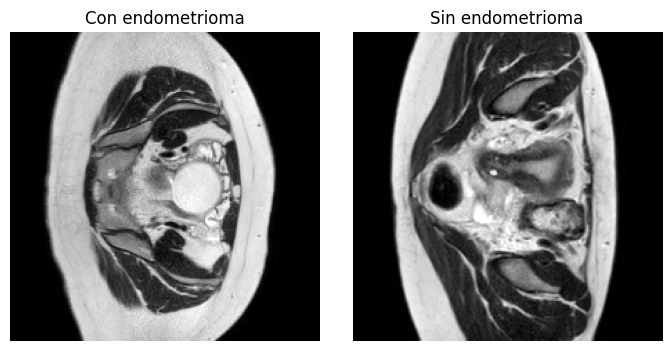

In [58]:
# Vista rápida: un corte con quiste y uno sin quiste
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))
for a, lab, t in zip(ax, [1, 0], ["Con endometrioma", "Sin endometrioma"]):
    idx = np.where(y == lab)[0]
    if len(idx):
        a.imshow(X[idx[len(idx) // 2]], cmap="gray")
    a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

## 5. Partición por paciente (70 / 15 / 15)

La división se hace **por paciente, no por corte**: cortes vecinos de la misma paciente son casi idénticos,
y si quedaran en entrenamiento y prueba a la vez las métricas saldrían infladas.

In [59]:
from sklearn.model_selection import train_test_split

pat = ok[["paciente", "tiene_quiste"]].reset_index(drop=True)
pat = pat[pat.paciente.isin(np.unique(groups))]

def split(df, test_size):
    strat = df.tiene_quiste if df.tiene_quiste.value_counts().min() >= 2 else None
    return train_test_split(df, test_size=test_size, stratify=strat, random_state=SEED)

train_p, temp_p = split(pat, 0.30)
val_p, test_p   = split(temp_p, 0.50)

def subset(pids):
    m = np.isin(groups, list(pids))
    return X[m], y[m], groups[m]

Xtr, ytr, gtr = subset(train_p.paciente)
Xva, yva, gva = subset(val_p.paciente)
Xte, yte, gte = subset(test_p.paciente)

particion = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validación", "Prueba"],
    "Pacientes": [len(train_p), len(val_p), len(test_p)],
    "Cortes": [len(ytr), len(yva), len(yte)],
    "Cortes positivos": [int(ytr.sum()), int(yva.sum()), int(yte.sum())],
    "% positivos": [f"{a.mean():.1%}" for a in (ytr, yva, yte)],
})
particion

,Conjunto,Pacientes,Cortes,Cortes positivos,% positivos
0,Entrenamiento,31,317,64,20.2%
1,Validación,7,68,7,10.3%
2,Prueba,7,60,7,11.7%


In [60]:
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision.transforms import v2 as T

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

augment = T.Compose([
    T.RandomHorizontalFlip(),
    T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
])

def to_input(batch_u8):
    # (N,H,W) uint8 -> (N,3,H,W) float normalizado (escala de grises replicada a 3 canales)
    x = batch_u8.float().div(255).unsqueeze(1).repeat(1, 3, 1, 1)
    return (x - MEAN.to(x.device)) / STD.to(x.device)

class SliceDataset(Dataset):
    def __init__(self, X, y, train=False):
        self.X, self.y, self.train = torch.from_numpy(X), torch.from_numpy(y), train
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        x = self.X[i].unsqueeze(0)                    # (1,H,W) uint8
        if self.train:
            x = augment(x)
        return x.squeeze(0), self.y[i]

# Muestreo balanceado: compensa que hay muchos más cortes sin quiste
counts = np.bincount(ytr, minlength=2).astype(float)
w = (1.0 / np.maximum(counts, 1))[ytr]
sampler = WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double), num_samples=len(ytr), replacement=True)

pin = DEVICE.type == "cuda"
train_loader = DataLoader(SliceDataset(Xtr, ytr, train=True), batch_size=BATCH_SIZE, sampler=sampler, num_workers=NUM_WORKERS, pin_memory=pin)
val_loader   = DataLoader(SliceDataset(Xva, yva), batch_size=BATCH_SIZE * 2, num_workers=NUM_WORKERS, pin_memory=pin)
test_loader  = DataLoader(SliceDataset(Xte, yte), batch_size=BATCH_SIZE * 2, num_workers=NUM_WORKERS, pin_memory=pin)
print("Lotes por época:", len(train_loader))

Lotes por época: 10


## 6. Definición de los tres modelos

In [61]:
import torch.nn as nn
from torchvision import models

class SimpleCNN(nn.Module):
    # Línea base: 4 bloques conv-BN-ReLU-pool, entrenada desde cero
    def __init__(self, n_classes=2):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o),
                                 nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

def build_model(name, pretrained=True):
    if name == "CNN propia":
        return SimpleCNN()
    if name == "ResNet18":
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, 2)
        return m
    if name == "EfficientNet-B0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT if pretrained else None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, 2)
        return m
    raise ValueError(name)

def ckpt_path(name):
    return OUT_DIR / f"{name.lower().replace(' ', '_').replace('-', '_')}_v3.pt"

def n_params(m):
    return sum(p.numel() for p in m.parameters()) / 1e6

for n in MODEL_NAMES:
    print(f"{n:<16} {n_params(build_model(n, pretrained=False)):6.2f} M parámetros")

CNN propia         0.39 M parámetros
ResNet18          11.18 M parámetros
EfficientNet-B0    4.01 M parámetros


## 7. Entrenamiento

AdamW + *cosine annealing*, precisión mixta en GPU y *early stopping* según el **F1 de validación**
(se guarda el mejor checkpoint de cada modelo en `OUT_DIR`). Si un checkpoint ya existe, se omite el entrenamiento;
borra el `.pt` para reentrenar.

In [62]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

@torch.no_grad()
def predict_loader(model, loader):
    model.eval()
    probs, labels = [], []
    for xb, yb in loader:
        xb = to_input(xb.to(DEVICE, non_blocking=True))
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(xb)
        probs.append(torch.softmax(logits.float(), 1)[:, 1].cpu()); labels.append(yb)
    return torch.cat(probs).numpy(), torch.cat(labels).numpy()

def train_model(name):
    set_seed()
    model = build_model(name).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR[name], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    loss_fn = nn.CrossEntropyLoss()
    best_auc, wait, hist = -1.0, 0, []
    t0 = time.perf_counter()
    for ep in range(1, EPOCHS + 1):
        model.train(); run_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = to_input(xb.to(DEVICE, non_blocking=True)), yb.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                loss = loss_fn(model(xb), yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run_loss += loss.item() * len(yb)
        sched.step()
        p, l = predict_loader(model, val_loader)
        f1 = f1_score(l, p >= THRESHOLD, zero_division=0)
        # AUC no depende del umbral: evita guardar un modelo que "nunca dice positivo" (F1 = 0 en todas las épocas)
        auc = roc_auc_score(l, p) if len(np.unique(l)) == 2 else f1
        hist.append({"modelo": name, "época": ep, "loss": run_loss / len(train_loader.dataset), "f1_val": f1, "auc_val": auc})
        print(f"[{name}] época {ep:02d} | loss {hist[-1]['loss']:.4f} | F1 val {f1:.3f} | AUC val {auc:.3f}")
        if auc > best_auc:
            best_auc, wait = auc, 0
            torch.save(model.state_dict(), ckpt_path(name))
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f"[{name}] early stopping en época {ep}")
                break
    return hist, time.perf_counter() - t0, best_auc

historial, tiempos_entrenamiento = [], {}
for name in MODEL_NAMES:
    if ckpt_path(name).exists():
        print(f"[{name}] checkpoint encontrado, se omite entrenamiento")
        continue
    h, secs, bf1 = train_model(name)
    historial += h; tiempos_entrenamiento[name] = secs
    print(f"[{name}] listo en {secs/60:.1f} min | mejor AUC val {bf1:.3f}\n")
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

[CNN propia] checkpoint encontrado, se omite entrenamiento
[ResNet18] época 01 | loss 0.5838 | F1 val 0.000 | AUC val 0.595
[ResNet18] época 02 | loss 0.2513 | F1 val 0.000 | AUC val 0.450
[ResNet18] época 03 | loss 0.2097 | F1 val 0.000 | AUC val 0.504
[ResNet18] época 04 | loss 0.0780 | F1 val 0.000 | AUC val 0.597
[ResNet18] época 05 | loss 0.1582 | F1 val 0.000 | AUC val 0.340
[ResNet18] época 06 | loss 0.1365 | F1 val 0.176 | AUC val 0.578
[ResNet18] época 07 | loss 0.1265 | F1 val 0.143 | AUC val 0.595
[ResNet18] época 08 | loss 0.0394 | F1 val 0.000 | AUC val 0.532
[ResNet18] época 09 | loss 0.0188 | F1 val 0.182 | AUC val 0.651
[ResNet18] época 10 | loss 0.0077 | F1 val 0.182 | AUC val 0.642
[ResNet18] época 11 | loss 0.0229 | F1 val 0.000 | AUC val 0.431
[ResNet18] época 12 | loss 0.0429 | F1 val 0.000 | AUC val 0.436
[ResNet18] época 13 | loss 0.0286 | F1 val 0.000 | AUC val 0.539
[ResNet18] época 14 | loss 0.0340 | F1 val 0.000 | AUC val 0.311
[ResNet18] época 15 | loss 0.03

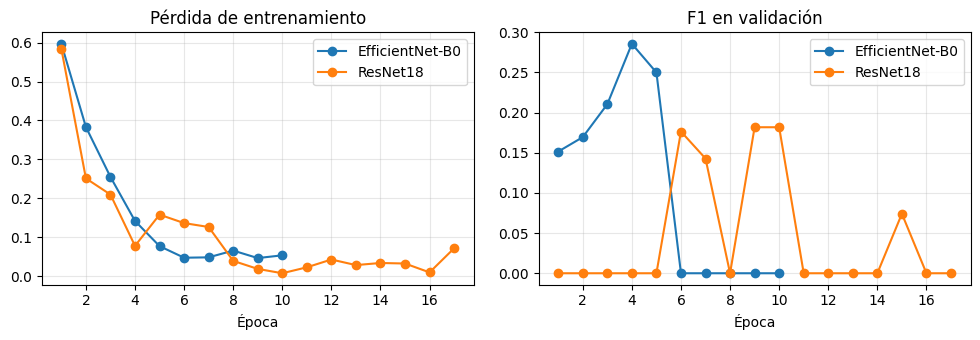

In [63]:
# Curvas de entrenamiento (si se entrenó en esta sesión)
if historial:
    hdf = pd.DataFrame(historial)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    for n, g in hdf.groupby("modelo"):
        ax[0].plot(g["época"], g["loss"], marker="o", label=n)
        ax[1].plot(g["época"], g["f1_val"], marker="o", label=n)
    ax[0].set_title("Pérdida de entrenamiento"); ax[1].set_title("F1 en validación")
    for a in ax: a.set_xlabel("Época"); a.grid(alpha=.3); a.legend()
    plt.tight_layout(); plt.show()

## 8. Carga de modelos

Se cargan los mejores pesos guardados de cada modelo en modo evaluación.

In [64]:
modelos = {}
for name in MODEL_NAMES:
    m = build_model(name, pretrained=False)
    m.load_state_dict(torch.load(ckpt_path(name), map_location=DEVICE, weights_only=True))
    modelos[name] = m.to(DEVICE).eval()
    print(f"Cargado {name:<16} <- {ckpt_path(name).name} ({ckpt_path(name).stat().st_size/1024**2:.1f} MB)")

# Calibración del umbral en VALIDACIÓN (nunca en prueba): con clases desbalanceadas 0.5 no es un buen corte.
# Se elige el umbral que maximiza F1 en validación; en empate se prefiere el más bajo (más recall).
THR = {}
for name, m in modelos.items():
    pv, lv = predict_loader(m, val_loader)
    cands = np.unique(np.round(pv, 4))
    f1s = [f1_score(lv, pv >= t, zero_division=0) for t in cands]
    THR[name] = float(cands[int(np.argmax(f1s))]) if len(cands) and max(f1s) > 0 else THRESHOLD
    print(f"Umbral {name:<16}: {THR[name]:.3f} (F1 val {max(f1s) if f1s else 0:.3f})")

Cargado CNN propia       <- cnn_propia_v3.pt (1.5 MB)
Cargado ResNet18         <- resnet18_v3.pt (42.7 MB)
Cargado EfficientNet-B0  <- efficientnet_b0_v3.pt (15.6 MB)
Umbral CNN propia      : 0.010 (F1 val 0.292)
Umbral ResNet18        : 0.012 (F1 val 0.300)
Umbral EfficientNet-B0 : 0.866 (F1 val 0.500)


## 9. Pipeline de inferencia

`infer_patient()` es lo que usaría el `ai_engine` de OVARA (igual que `app.py` en DocuAI):
**NIfTI → preprocesamiento → predicción por corte → veredicto por paciente.**

En inferencia real no hay máscaras, así que se evalúan **todos** los cortes del volumen. La paciente se marca como
*sugiere endometrioma* si al menos `MIN_POS_SLICES` cortes superan el umbral.

In [65]:
@torch.no_grad()
def predict_slices(model, slices_u8, batch_size=64):
    probs = []
    for i in range(0, len(slices_u8), batch_size):
        xb = to_input(torch.from_numpy(slices_u8[i:i + batch_size]).to(DEVICE))
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            probs.append(torch.softmax(model(xb).float(), 1)[:, 1].cpu())
    return torch.cat(probs).numpy()

def infer_patient(model, folder: Path, threshold=THRESHOLD, min_pos=MIN_POS_SLICES):
    _, _, slices = preprocess_volume(nifti_path(folder, SEQUENCE))
    probs = predict_slices(model, slices)
    pos = np.where(probs >= threshold)[0]
    return {
        "paciente": folder.name,
        "cortes": len(probs),
        "cortes_positivos": len(pos),
        "prob_max": float(probs.max()),
        "corte_mas_sospechoso": int(probs.argmax()),
        "prediccion": int(len(pos) >= min_pos),
        "veredicto": "Sugiere endometrioma — revisar" if len(pos) >= min_pos else "Sin hallazgos sugestivos",
    }

# Ejemplo con una paciente de prueba
ejemplo = DATA_DIR / test_p.paciente.iloc[0]
pd.DataFrame([{"modelo": n, **infer_patient(m, ejemplo, threshold=THR[n])} for n, m in modelos.items()])

,modelo,paciente,cortes,cortes_positivos,prob_max,corte_mas_sospechoso,prediccion,veredicto
0,CNN propia,D2-055,39,1,0.010499,3,0,Sin hallazgos sugestivos
1,ResNet18,D2-055,39,0,0.010871,22,0,Sin hallazgos sugestivos
2,EfficientNet-B0,D2-055,39,0,0.761228,18,0,Sin hallazgos sugestivos


## 10. Cálculo de métricas (conjunto de prueba)

* **Accuracy:** proporción de aciertos totales.
* **Precision:** de los cortes marcados como positivos, cuántos lo eran (evita falsas alarmas).
* **Recall (sensibilidad):** de los cortes positivos reales, cuántos se detectaron. **Clínicamente es la más importante.**
* **F1-score:** media armónica de precision y recall.

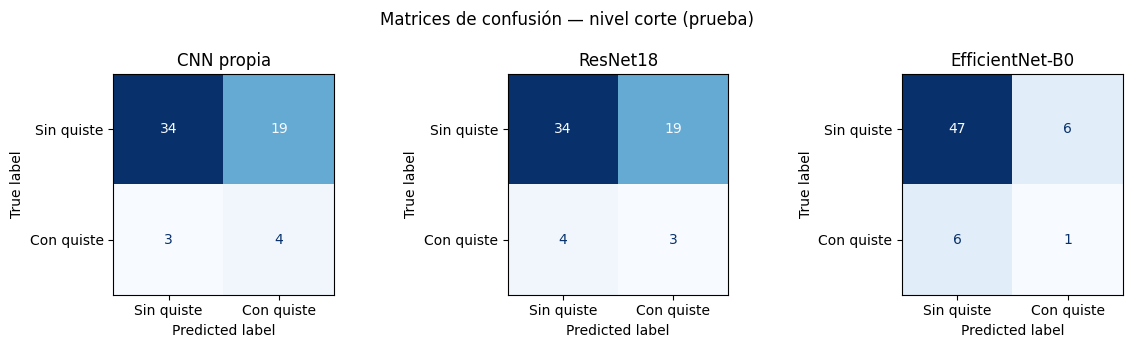

Métricas por CORTE (prueba)


,Umbral,Accuracy,Precision,Recall,F1-score,AUC
Modelo,,,,,,
CNN propia,0.010,0.633,0.174,0.571,0.267,0.601
ResNet18,0.012,0.617,0.136,0.429,0.207,0.617
EfficientNet-B0,0.866,0.800,0.143,0.143,0.143,0.491


Métricas por PACIENTE (prueba)


,Accuracy,Precision,Recall,F1-score
Modelo,,,,
CNN propia,0.429,0.333,1.0,0.5
ResNet18,0.429,0.333,1.0,0.5
EfficientNet-B0,0.571,0.000,0.0,0.0


In [66]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def metricas(y_true, y_pred, y_prob=None):
    d = {"Accuracy": accuracy_score(y_true, y_pred),
         "Precision": precision_score(y_true, y_pred, zero_division=0),
         "Recall": recall_score(y_true, y_pred, zero_division=0),
         "F1-score": f1_score(y_true, y_pred, zero_division=0)}
    if y_prob is not None and len(np.unique(y_true)) == 2:
        d["AUC"] = roc_auc_score(y_true, y_prob)
    return d

# --- Nivel corte ---
filas_corte, preds_test = [], {}
for name, m in modelos.items():
    p, l = predict_loader(m, test_loader)
    preds_test[name] = (p, l)
    filas_corte.append({"Modelo": name, "Umbral": THR[name], **metricas(l, p >= THR[name], p)})
tabla_corte = pd.DataFrame(filas_corte).set_index("Modelo")

fig, ax = plt.subplots(1, len(modelos), figsize=(4 * len(modelos), 3.5))
for a, (name, (p, l)) in zip(np.atleast_1d(ax), preds_test.items()):
    ConfusionMatrixDisplay(confusion_matrix(l, p >= THR[name], labels=[0, 1]),
                           display_labels=["Sin quiste", "Con quiste"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(name)
plt.suptitle("Matrices de confusión — nivel corte (prueba)"); plt.tight_layout(); plt.show()

# --- Nivel paciente (pipeline completo, todos los cortes) ---
filas_pac, detalle_pac = [], []
for name, m in modelos.items():
    yt, yp = [], []
    for pid, label in zip(test_p.paciente, test_p.tiene_quiste.astype(int)):
        r = infer_patient(m, DATA_DIR / pid, threshold=THR[name])
        yt.append(label); yp.append(r["prediccion"])
        detalle_pac.append({"modelo": name, "real": label, **r})
    filas_pac.append({"Modelo": name, **metricas(np.array(yt), np.array(yp))})
tabla_paciente = pd.DataFrame(filas_pac).set_index("Modelo")

print("Métricas por CORTE (prueba)"); display(tabla_corte.round(3))
print("Métricas por PACIENTE (prueba)"); display(tabla_paciente.round(3))

## 11. Medición de latencia

* **Latencia por corte (batch = 1):** tiempo de una predicción individual (media y percentil 95).
* **Throughput (batch = 32):** cortes por segundo procesando en lote.
* **Tiempo por paciente (end-to-end):** leer NIfTI + preprocesar + inferir todos los cortes.

Se hacen iteraciones de calentamiento y `torch.cuda.synchronize()` para medir el tiempo real de la GPU
(las llamadas a CUDA son asíncronas).

In [67]:
def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

@torch.no_grad()
def medir_latencia(model, batch_size, n_warmup=10, n_runs=50):
    x = torch.randn(batch_size, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
    for _ in range(n_warmup):
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            model(x)
    sync()
    tiempos = []
    for _ in range(n_runs):
        t0 = time.perf_counter()
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            model(x)
        sync()
        tiempos.append((time.perf_counter() - t0) * 1000)
    return np.array(tiempos)

pacientes_lat = list(test_p.paciente[:5])
filas_lat = []
for name, m in modelos.items():
    t1 = medir_latencia(m, 1)
    t32 = medir_latencia(m, 32, n_runs=20)
    e2e = []
    for pid in pacientes_lat:
        sync(); t0 = time.perf_counter()
        infer_patient(m, DATA_DIR / pid)
        sync(); e2e.append(time.perf_counter() - t0)
    filas_lat.append({
        "Modelo": name,
        "Parámetros (M)": n_params(m),
        "Tamaño (MB)": ckpt_path(name).stat().st_size / 1024**2,
        "Latencia/corte media (ms)": t1.mean(),
        "Latencia/corte p95 (ms)": np.percentile(t1, 95),
        "Throughput (cortes/s)": 32 / (t32.mean() / 1000),
        "Tiempo/paciente (s)": np.mean(e2e),
    })
tabla_latencia = pd.DataFrame(filas_lat).set_index("Modelo")
if DEVICE.type == "cuda":
    print(f"VRAM máxima usada: {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")
tabla_latencia.round(2)

VRAM máxima usada: 1.51 GB


,Parámetros (M),Tamaño (MB),Latencia/corte media (ms),Latencia/corte p95 (ms),Throughput (cortes/s),Tiempo/paciente (s)
Modelo,,,,,,
CNN propia,0.39,1.50,1.08,1.40,4101.07,0.24
ResNet18,11.18,42.71,3.08,3.55,2896.21,0.24
EfficientNet-B0,4.01,15.59,10.21,14.89,2160.60,0.25


## 12. Tablas resumen

In [68]:
resumen = pd.concat([
    tabla_corte[["Accuracy", "Precision", "Recall", "F1-score"]].add_suffix(" (corte)"),
    tabla_paciente[["Recall", "F1-score"]].add_suffix(" (paciente)"),
    tabla_latencia[["Parámetros (M)", "Latencia/corte media (ms)", "Throughput (cortes/s)", "Tiempo/paciente (s)"]],
], axis=1)
if tiempos_entrenamiento:
    resumen["Entrenamiento (min)"] = pd.Series(tiempos_entrenamiento) / 60

resumen.round(3).to_csv(OUT_DIR / "resumen_modelos.csv", encoding="utf-8-sig")
pd.DataFrame(detalle_pac).to_csv(OUT_DIR / "detalle_pacientes_prueba.csv", index=False, encoding="utf-8-sig")
print("Guardado en", (OUT_DIR / "resumen_modelos.csv").resolve())

(resumen.style.format(precision=3)
       .highlight_max(subset=[c for c in resumen.columns if "(corte)" in c or "(paciente)" in c or "Throughput" in c], color="#c6efce")
       .highlight_min(subset=["Latencia/corte media (ms)", "Tiempo/paciente (s)"], color="#c6efce"))

Guardado en C:\Proyectos\AI\OVARA\resultados_ovara\resumen_modelos.csv


,Accuracy (corte),Precision (corte),Recall (corte),F1-score (corte),Recall (paciente),F1-score (paciente),Parámetros (M),Latencia/corte media (ms),Throughput (cortes/s),Tiempo/paciente (s),Entrenamiento (min)
Modelo,,,,,,,,,,,
CNN propia,0.633,0.174,0.571,0.267,1.000,0.500,0.389,1.079,4101.071,0.237,nan
ResNet18,0.617,0.136,0.429,0.207,1.000,0.500,11.178,3.077,2896.215,0.242,0.237
EfficientNet-B0,0.800,0.143,0.143,0.143,0.000,0.000,4.010,10.206,2160.599,0.248,0.245


## 13. Conclusiones

La siguiente celda genera un resumen automático con los resultados de esta ejecución.

In [69]:
mejor_f1  = tabla_corte["F1-score"].idxmax()
mejor_rec = tabla_corte["Recall"].idxmax()
mas_rap   = tabla_latencia["Latencia/corte media (ms)"].idxmin()
base_f1   = tabla_corte.loc["CNN propia", "F1-score"]

print(f"• Mejor F1 por corte: {mejor_f1} ({tabla_corte.loc[mejor_f1, 'F1-score']:.3f}); "
      f"la CNN propia logra {base_f1:.3f}.")
print(f"• Mayor sensibilidad (recall): {mejor_rec} ({tabla_corte.loc[mejor_rec, 'Recall']:.3f}).")
print(f"• Más rápido: {mas_rap} ({tabla_latencia.loc[mas_rap, 'Latencia/corte media (ms)']:.2f} ms/corte, "
      f"{tabla_latencia.loc[mas_rap, 'Tiempo/paciente (s)']:.2f} s por paciente).")
if mejor_f1 == mas_rap:
    print(f"• {mejor_f1} es a la vez el más preciso y el más rápido: es el candidato claro para el ai_engine de OVARA.")
else:
    print(f"• Compromiso: {mejor_f1} es más preciso y {mas_rap} más rápido; "
          f"como todos procesan una paciente en segundos, se prioriza {mejor_f1} por desempeño.")

• Mejor F1 por corte: CNN propia (0.267); la CNN propia logra 0.267.
• Mayor sensibilidad (recall): CNN propia (0.571).
• Más rápido: CNN propia (1.08 ms/corte, 0.24 s por paciente).
• CNN propia es a la vez el más preciso y el más rápido: es el candidato claro para el ai_engine de OVARA.


**Conclusiones generales**

* Los modelos **preentrenados** (ResNet18, EfficientNet-B0) suelen superar a la CNN propia con pocos datos, porque reutilizan
  características visuales aprendidas en ImageNet.
* Las tres redes infieren en **milisegundos por corte** en GPU, por lo que la latencia no es el cuello de botella: la elección
  se basa en **recall** (no dejar pasar casos) y F1.
* **Limitaciones:** la etiqueta se deriva de la máscara de quistes (detecta *endometriomas*, no todas las formas de endometriosis);
  el dataset es pequeño y de una sola cohorte; las métricas por paciente tienen alta varianza con pocos casos de prueba.
* **Siguiente paso:** pasar de clasificación a **segmentación** (nnU-Net) para entregar al ginecólogo la ubicación y el volumen
  del quiste, más útil como apoyo al veredicto médico en OVARA.